# Text-to-SQL con agentes locales: ¿agente único o multiagente?

**Caso de uso.** *Tienda Andina* (empresa ficticia) quiere que cualquier persona pregunte en español sobre sus ventas
("¿qué ciudad tiene más pedidos?") y obtenga la respuesta consultando su base SQLite. El sistema traduce la pregunta a SQL,
la ejecuta y devuelve el resultado.

**Por qué este caso.** La calidad se mide de forma **objetiva**: el SQL generado se ejecuta y su resultado se compara con el
de una consulta de referencia (*exactitud por ejecución*). No hace falta un juez LLM, que con modelos pequeños es poco confiable.

**Modelos (locales, Ollama).** Dos modelos asignados por rol, ambos cargados a la vez en una GTX 1650 Ti de 4 GB:

| Modelo | Tamaño | Rol |
|---|---|---|
| `qwen2.5-coder:1.5b` | 986 MB | router y preguntas simples (rápido, ~100 tokens/s) |
| `qwen2.5-coder:3b` | 1.9 GB | preguntas complejas y corrector (~43 tokens/s) |

**Datos.** 5 tablas (`categorias`, `productos`, `clientes`, `pedidos`, `detalle_pedido`), 24 preguntas con SQL de referencia
(12 simples y 12 complejas) y 12 variantes con errores de ortografía y lenguaje informal para medir robustez.

## Arquitecturas comparadas

Se usan **dos patrones** (router y evaluador-optimizador) y su combinación, contra el agente único como línea base:

| Config. | Qué hace |
|---|---|
| **A · único 1.5b** | un agente con el modelo pequeño y un prompt general |
| **B · único 3b** | un agente con el modelo grande y un prompt general |
| **C · router** | el 1.5b clasifica la pregunta: simple → 1.5b con prompt corto; compleja → 3b con esquema completo y ejemplos |
| **D · evaluador-optimizador** (cascada) | el 1.5b genera; un evaluador **ejecuta** el SQL (0 tokens) y, si falla o sale vacío, un corrector 3b lo reescribe (máx. 2 veces) |
| **E · router + evaluador** | C seguido de D |

```
pregunta ─▶ router (1.5b) ─┬─ simple ──▶ generador 1.5b (prompt corto) ──┐
                           └─ compleja ─▶ generador 3b (esquema+ejemplos)┤
                                                                         ▼
                                       ┌──── corrector 3b ◀── problema ─ evaluador (ejecuta SQL)
                                       └──────────────────────────────▶      │ ok
                                                                             ▼
                                                                          resultado
```

Cada arquitectura está implementada **dos veces** con la misma lógica, modelos y prompts:

- `sin_framework.py`: Python puro + cliente `ollama`. Un solo punto (`llamar_llm`) mide tokens y tiempo.
- `con_langgraph.py`: `StateGraph` de LangGraph + `ChatOllama`. El router es una arista desde `START`, el
  evaluador-optimizador es un ciclo `evaluador ⇄ corrector` y las trazas se toman con un *callback*.

Ambas versiones envían trazas a **LangSmith** si se define `LANGSMITH_TRACING=true` y `LANGSMITH_API_KEY` en `.env`.

## Cómo se mide cada métrica

| Métrica | Medida |
|---|---|
| **Calidad** | exactitud por ejecución (% de preguntas cuyo resultado coincide con la referencia), total y por tipo |
| **Costo** | tokens por tarea, llamadas al LLM y USD por millón de tareas con precios de API de referencia (*supuesto*: con Ollama el costo real es $0) |
| **Latencia** | tiempo de reloj por tarea: media y percentil 95; *overhead* no-LLM = tiempo total − tiempo en el modelo |
| **Robustez** | exactitud con preguntas ruidosas, % de SQL que no ejecuta, caídas del sistema |
| **Coordinación** | % de tokens y de tiempo gastado en agentes que no generan la respuesta principal (router, corrector), correcciones por tarea y acierto del router |

Para volver a correr todo: `uv run python experimento.py` (unos minutos) y luego las celdas de abajo.

In [1]:
import pandas as pd
from IPython.display import Image, display
import analisis

pd.set_option("display.max_columns", 30, "display.width", 200)
tareas = analisis.cargar()
m = analisis.metricas(tareas)
analisis.graficas(tareas, m)
print(len(tareas), "tareas")

360 tareas


## Resultados: las 5 métricas

In [2]:
cols = {
    "Calidad": ["exactitud %", "exactitud simples %", "exactitud complejas %"],
    "Costo": ["tokens/tarea", "llamadas LLM/tarea", "USD por millón de tareas*"],
    "Latencia": ["latencia media s", "latencia p95 s", "overhead no-LLM ms"],
    "Robustez": ["exactitud con ruido %", "SQL inválido %", "caídas del sistema"],
    "Coordinación": ["% tokens coordinación", "% tiempo coordinación", "correcciones/tarea", "acierto del router %"],
}
for titulo, c in cols.items():
    print(f"\n=== {titulo} ===")
    display(m.set_index(["implementación", "configuración"])[c])


=== Calidad ===


exactitud %  exactitud simples %  exactitud complejas %
implementación configuración                                                                     
sin framework  A · único 1.5b                   79.17                75.00                  83.33
               B · único 3b                     87.50               100.00                  75.00
               C · router                       83.33                83.33                  83.33
               D · evaluador-optimizador        87.50                91.67                  83.33
               E · router + evaluador           91.67               100.00                  83.33
LangGraph      A · único 1.5b                   79.17                75.00                  83.33
               B · único 3b                     87.50               100.00                  75.00
               C · router                       83.33                83.33                  83.33
               D · evaluador-optimizador        87.50                91.67                  83.33
               E · router + evaluador           91.67               100.00                  83.33


=== Costo ===


tokens/tarea  llamadas LLM/tarea  USD por millón de tareas*
implementación configuración                                                                         
sin framework  A · único 1.5b                   279.17                1.00                       9.71
               B · único 3b                     269.92                1.00                      18.31
               C · router                       522.62                2.00                      24.25
               D · evaluador-optimizador        350.50                1.17                      14.81
               E · router + evaluador           564.04                2.12                      27.00
LangGraph      A · único 1.5b                   279.17                1.00                       9.71
               B · único 3b                     269.92                1.00                      18.31
               C · router                       522.62                2.00                      24.25
               D · evaluador-optimizador        350.50                1.17                      14.81
               E · router + evaluador           564.04                2.12                      27.00


=== Latencia ===


latencia media s  latencia p95 s  overhead no-LLM ms
implementación configuración                                                                  
sin framework  A · único 1.5b                         0.52            0.96                0.25
               B · único 3b                           1.12            2.17                0.35
               C · router                             1.00            2.36                0.50
               D · evaluador-optimizador              1.00            1.71                0.80
               E · router + evaluador                 1.15            2.57                1.00
LangGraph      A · único 1.5b                         0.55            1.00                2.05
               B · único 3b                           1.13            2.20                1.71
               C · router                             0.99            2.33                2.80
               D · evaluador-optimizador              1.01            1.74                3.72
               E · router + evaluador                 1.18            2.71                4.43


=== Robustez ===


exactitud con ruido %  SQL inválido %  caídas del sistema
implementación configuración                                                                       
sin framework  A · único 1.5b                             58.33           16.67                   0
               B · único 3b                              100.00            0.00                   0
               C · router                                 75.00           16.67                   0
               D · evaluador-optimizador                  75.00            2.78                   0
               E · router + evaluador                     83.33            5.56                   0
LangGraph      A · único 1.5b                             58.33           16.67                   0
               B · único 3b                              100.00            0.00                   0
               C · router                                 75.00           16.67                   0
               D · evaluador-optimizador                  66.67            2.78                   0
               E · router + evaluador                     83.33            5.56                   0


=== Coordinación ===


% tokens coordinación  % tiempo coordinación  correcciones/tarea  acierto del router %
implementación configuración                                                                                                    
sin framework  A · único 1.5b                              0.00                   0.00                0.00                   NaN
               B · único 3b                                0.00                   0.00                0.00                   NaN
               C · router                                 37.99                   9.84                0.00                  87.5
               D · evaluador-optimizador                  20.35                  45.94                0.17                   NaN
               E · router + evaluador                     42.54                  23.22                0.12                  87.5
LangGraph      A · único 1.5b                              0.00                   0.00                0.00                   NaN
               B · único 3b                                0.00                   0.00                0.00                   NaN
               C · router                                 37.99                   9.84                0.00                  87.5
               D · evaluador-optimizador                  20.35                  45.60                0.17                   NaN
               E · router + evaluador                     42.54                  22.76                0.12                  87.5

### Calidad frente a latencia y costo
Arriba a la izquierda es mejor: más exactitud con menos tiempo o menos tokens.

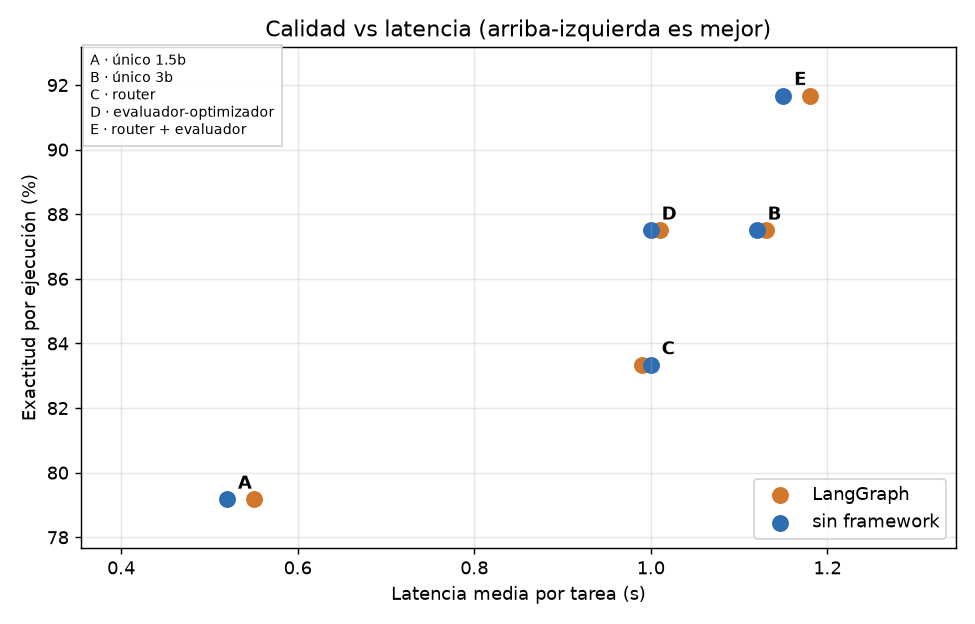

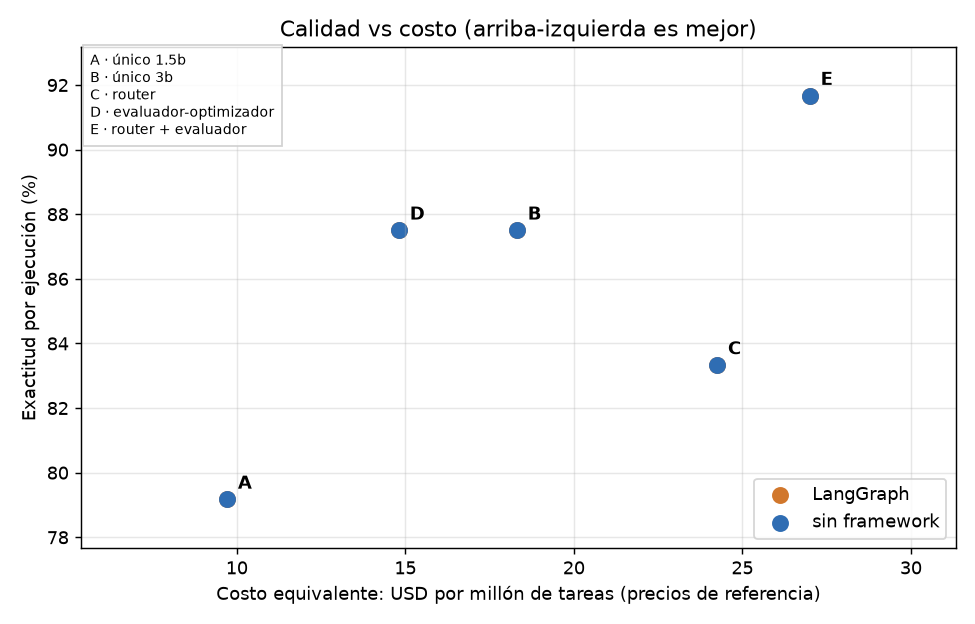

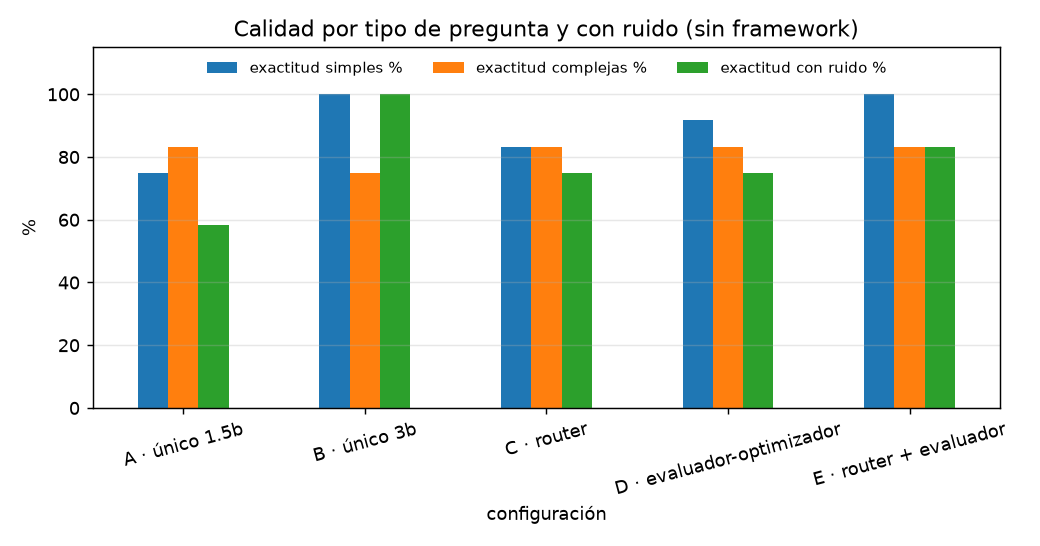

In [3]:
display(Image("resultados/pareto_latencia.png"))
display(Image("resultados/pareto_costo.png"))
display(Image("resultados/calidad_detalle.png"))

### ¿En qué preguntas falla cada configuración?

In [4]:
fallos = tareas[(tareas.implementacion == "sin framework") & ~tareas.correcta.astype(bool)]
display(pd.crosstab([fallos.dataset, fallos.id], fallos.config).replace({0: "", 1: "✗"}))

config      A · único 1.5b B · único 3b C · router D · evaluador-optimizador E · router + evaluador
dataset id                                                                                         
normal  c08              ✗            ✗          ✗                         ✗                      ✗
        c11                           ✗                                                            
        c12              ✗            ✗          ✗                         ✗                      ✗
        s03              ✗                                                 ✗                       
        s08              ✗                       ✗                                                 
        s12              ✗                       ✗                                                 
ruido   r03              ✗                       ✗                         ✗                      ✗
        r05              ✗                       ✗                                                 
        r09              ✗                                                 ✗                       
        r10              ✗                       ✗                                                ✗
        r12              ✗                                                 ✗

### Router: ¿clasifica bien?

In [5]:
r = tareas[tareas.ruta.notna() & (tareas.dataset == "normal")]
display(pd.crosstab(r.nivel, r.ruta, rownames=["nivel real"], colnames=["ruta elegida"]))

ruta elegida,compleja,simple
nivel real,,
compleja,40,8
simple,4,44


### Con framework vs sin framework
Misma lógica: las diferencias de calidad deberían ser cero; lo que cambia es el *overhead* de orquestación.

In [6]:
comp = tareas[tareas.dataset == "normal"].groupby(["config", "implementacion"])[["correcta", "latencia_s", "overhead_s"]].mean()
comp["overhead_s"] *= 1000
display(comp.rename(columns={"overhead_s": "overhead ms"}).round(3).unstack())

correcta               latencia_s               overhead ms              
implementacion            LangGraph sin framework  LangGraph sin framework   LangGraph sin framework
config                                                                                              
A · único 1.5b                0.792         0.792      0.545         0.522       2.049         0.252
B · único 3b                  0.875         0.875      1.132         1.125       1.712         0.347
C · router                    0.833         0.833      0.986         0.999       2.801         0.505
D · evaluador-optimizador     0.875         0.875      1.009         0.998       3.720         0.803
E · router + evaluador        0.917         0.917      1.185         1.150       4.429         0.999

## Conclusiones

Resultados de la corrida final: 24 preguntas normales + 12 con ruido, 5 configuraciones, 2 implementaciones (360 tareas)
en una GTX 1650 Ti de 4 GB.

| | A · único 1.5b | B · único 3b | C · router | **D · cascada (evaluador)** | **E · router + evaluador** |
|---|---|---|---|---|---|
| Calidad (exactitud) | 79.2 % | 87.5 % | 83.3 % | **87.5 %** | **91.7 %** |
| Costo (USD / millón de tareas*) | 9.7 | 18.3 | 24.3 | **14.8** | 27.0 |
| Latencia media / p95 (s) | 0.52 / 0.96 | 1.12 / 2.17 | 1.00 / 2.36 | **1.00 / 1.71** | 1.15 / 2.57 |
| Robustez (exactitud con ruido) | 58 % | 100 % | 75 % | 75 % | 83 % |
| Coordinación (% tokens / % tiempo) | 0 / 0 | 0 / 0 | 38 / 10 | 20 / 46 | 43 / 23 |

\* Con Ollama el costo real es $0; el USD usa precios de referencia supuestos (el 3b cuesta el doble por token que el 1.5b).

**1. La mejor relación costo-latencia es la cascada D (evaluador-optimizador con dos modelos).**
Genera el modelo barato (1.5b) y solo si el evaluador encuentra un error (SQL que no ejecuta o que devuelve vacío)
escala al 3b para corregirlo. Iguala la calidad del 3b solo (87.5 %) siendo **19 % más barata**, **11 % más rápida
en promedio** y **21 % más rápida en el p95**. El evaluador cuesta 0 tokens porque no es un LLM: ejecuta la consulta.

**2. La mejor calidad es E (router + evaluador): 91.7 %**, +4.2 puntos sobre el 3b solo, con casi la misma latencia
(+3 %) pero +47 % de costo. Es la opción si la calidad pesa más que el costo.

**3. El router solo (C) no compensa.** Manda las preguntas simples al 1.5b sin red de seguridad, y el 1.5b usa
funciones de MySQL (`MONTH()`, `YEAR()`) que no existen en SQLite: 16.7 % de SQL inválido. Los dos patrones se
complementan: el router ahorra en lo fácil y el evaluador atrapa los errores del modelo barato.

**4. Diseñar para modelos pequeños.** Un 1.5b como clasificador directo ("SIMPLE o COMPLEJA") acertó solo el 58 %:
respondía "COMPLEJA" casi siempre. Pedirle que **nombre las tablas** y decidir con una regla subió el acierto a 87.5 %.
Sus errores restantes (preguntas con "nunca") caen en el 1.5b, que resuelve bien esas preguntas.

**5. Robustez.** Con preguntas mal escritas, el 3b solo es el más robusto (100 %). El 1.5b se confunde con errores
de ortografía ("prodcto mas carro"), y eso arrastra a C, D y E. Ninguna configuración se cayó (0 excepciones) y el
evaluador bajó el SQL inválido del 1.5b de 16.7 % a 2.8 %.

**6. Costo de coordinar.** En D la coordinación es el 20 % de los tokens pero el 46 % del tiempo: el corrector
interviene solo en el 17 % de las tareas, pero usa el modelo grande y es la parte lenta (peor caso ≈ 10 s). En E, el
router se lleva la mayor parte de los tokens extra (su prompt incluye el esquema).

**7. Con framework o sin framework da igual en calidad y latencia.** Misma lógica, mismos números. LangGraph agrega
2–4 ms por tarea frente a ~1000 ms del modelo, y solo hay una diferencia de una pregunta en D con ruido (pequeño no
determinismo entre clientes). LangGraph aporta el grafo declarativo, el ciclo evaluador ⇄ corrector explícito y las
trazas automáticas en LangSmith. Sin framework, el código es más corto y fácil de depurar.

**8. Lección de hardware.** Con 4 GB de VRAM, Ollama descargaba un modelo para cargar el otro (≈ 10 s por cambio), y
eso hacía al multiagente más lento que el agente único. Fijar las capas en GPU por modelo (`CAPAS_GPU`) mantiene los
dos cargados a la vez. El tope de 160 tokens de salida evitó respuestas largas del corrector.

**Limitaciones.** 24 preguntas es una muestra pequeña: una pregunta equivale a 4.2 puntos de exactitud. Los precios
son supuestos y se corrió con temperatura 0, así que cada configuración se midió una vez.
